# 04 – SARIMA and SARIMAX

Classical models of lecture 4 (CLAUDE.md section 6), the "classical" row of the two-way table:

| Model | Inputs |
|---|---|
| `sarima` | prices only, SARIMA(1,0,1)(1,1,1)₂₄ |
| `sarimax` | same orders + exogenous variables `load_fc`, `wind_fc`, `solar_fc`, `non_working_day` |

The orders were selected on the pre-test period only (`02_exploration.ipynb`, section 7) and are **frozen** in `src/config.py`. The exogenous variables are the same as for the foundation models with covariates (`05_foundation.ipynb`). They are day-ahead **forecasts**, over the fit window as for day D.

Both models are run with the common rolling loop (`src.evaluation.run_rolling`) on the main test period and on the control period. They return no quantiles (empty `q10` … `q90` columns). Forecasts are cached in `results/` and `results/control/`.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox

from src import config as cfg
from src.baselines import NaiveReference
from src.data import load_dataset, split_for_day
from src.evaluation import mae, rmse, run_rolling
from src.sarima import Sarima

df = load_dataset()
CONTROL_DAYS = pd.date_range(cfg.CONTROL_START, cfg.CONTROL_END, freq="D")
ONE_HOUR = pd.Timedelta(hours=1)

print(f"Dataset: {df.index[0]} → {df.index[-1]}")
print(f"Main test: {len(cfg.TEST_DAYS)} days, control: {len(CONTROL_DAYS)} days ({CONTROL_DAYS[0].date()} → {CONTROL_DAYS[-1].date()})")
print(f"Orders: SARIMA{cfg.SARIMA_ORDER}{cfg.SARIMA_SEASONAL_ORDER[:3]}, s = {cfg.SARIMA_SEASONAL_ORDER[3]}; SARIMAX exog: {cfg.EXOG}")

Dataset: 2023-01-01 00:00:00 → 2026-11-08 23:00:00
Main test: 183 days, control: 24 days (2026-10-16 → 2026-11-08)
Orders: SARIMA(1, 0, 1)(1, 1, 1), s = 24; SARIMAX exog: ['load_fc', 'wind_fc', 'solar_fc', 'non_working_day']


## 1. Models and estimation schedule

**SARIMA** (Box-Jenkins notation, B = backshift operator, s = 24):

$$
(1 - \phi_1 B)(1 - \Phi_1 B^{24})\,(1 - B^{24})\, y_t = (1 + \theta_1 B)(1 + \Theta_1 B^{24})\, \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal N(0, \sigma^2)
$$

**SARIMAX** is a regression with SARIMA errors (the `statsmodels` formulation): the price is a linear function of the exogenous variables plus an error $u_t$ that follows the same SARIMA model,

$$
y_t = \beta_1\,\text{load\_fc}_t + \beta_2\,\text{wind\_fc}_t + \beta_3\,\text{solar\_fc}_t + \beta_4\,\text{non\_working\_day}_t + u_t .
$$

For day D, the regressors over the fit window come from `history` and those of the 24 hours of D from `future_cov` (day-ahead forecasts of D and calendar). No constant: with the seasonal difference, it would be a drift.

**Schedule** (CLAUDE.md section 6): the parameters are **re-estimated every Monday** on the last 8 weeks (1,344 h) before Monday 00:00, by maximum likelihood (`statsmodels.tsa.statespace.sarimax.SARIMAX(...).fit()`, default settings except the iteration budget of the optimizer, see section 3). On Tuesday to Sunday, the parameters are kept and the observations from Monday 00:00 to D−1 23:00 are added to the model state with `MLEResults.append(new_endog, exog=new_exog, refit=False)`. From the `statsmodels` documentation: *"Creates a new result object applied to a dataset that is created by appending new data to the end of the model's original data"*; with `refit=False` (the default), *"parameters from the current results object are used to create the new results object"*. The Kalman filter runs with the Monday parameters over the window plus the new days, so the forecast starts from the last observed price (D−1 23:00). (`extend` would only filter the new observations, which is faster but gives the same state; `append` is used, as in the order selection.)

The parameters used on day D are always those of the Monday of its week. The main test starts on a Wednesday (1 April 2026): its first two days use the fit of Monday 30 March, on the 8 weeks before it, which only contain pre-test data. The control period starts on a Friday (16 October) and uses the fit of Monday 12 October. This makes the forecast of a day independent of the first day of the run.

The model only receives `history` (up to D−1 23:00) and `future_cov` (covariates and calendar of D, without the price). Implementation: `src/sarima.py`, tested in `tests/test_sarima.py`.

### 1.1 Check on one week

First week of the main test (Wednesday 1 April → Tuesday 7 April 2026). The two models are refitted here on Monday 30 March and Monday 6 April (≈ 7 s per SARIMA fit, ≈ 20 s per SARIMAX fit on CPU).

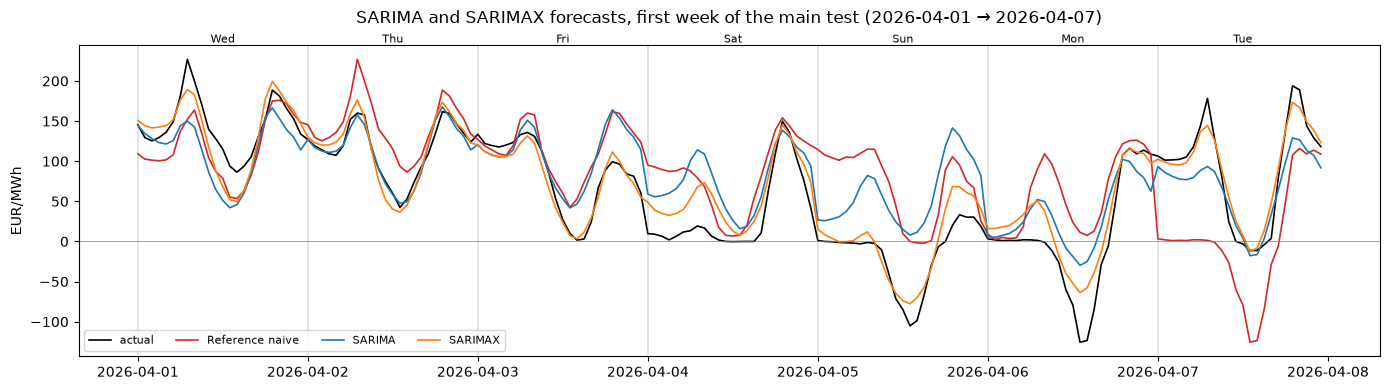

Weekly fits used in this check:


converged  iterations  n_warnings warnings  ar.L1  ma.L1  \
        fit_day                                                                
sarima  2026-03-30       True          18           0           0.908  0.419   
        2026-04-06       True          22           0           0.924  0.405   
sarimax 2026-03-30       True          34           0           0.779  0.354   
        2026-04-06       True          46           0           0.772  0.345   

                    ar.S.L24  ma.S.L24   sigma2  load_fc  wind_fc  solar_fc  \
        fit_day                                                               
sarima  2026-03-30     0.067    -0.829  103.264      NaN      NaN       NaN   
        2026-04-06     0.068    -0.810  118.143      NaN      NaN       NaN   
sarimax 2026-03-30     0.073    -0.877   77.520    2.833   -2.408    -3.193   
        2026-04-06     0.058    -0.862   86.545    3.089   -2.652    -3.152   

                    non_working_day  
        fit_day                      
sarima  2026-03-30              NaN  
        2026-04-06              NaN  
sarimax 2026-03-30           -0.287  
        2026-04-06            0.497

In [ ]:
labels = {"naive_ref": "Reference naive", "sarima": "SARIMA", "sarimax": "SARIMAX"}
colors = {"naive_ref": "C3", "sarima": "C0", "sarimax": "C1", "naive_d1": "C7"}

week = cfg.TEST_DAYS[:7]
week_models = {"naive_ref": NaiveReference(), "sarima": Sarima(), "sarimax": Sarima(exog=cfg.EXOG)}
fig, ax = plt.subplots(figsize=(14, 4))
actual = df.loc[week[0] : week[-1] + 23 * ONE_HOUR, cfg.TARGET]
ax.plot(actual.index, actual, color="k", lw=1.2, label="actual")
for name, model in week_models.items():
    forecasts = []
    for day in week:
        history, future_cov = split_for_day(df, day)
        y_pred, _ = model.predict(history, future_cov)
        forecasts.append(pd.Series(y_pred, index=future_cov.index))
    forecast = pd.concat(forecasts)
    ax.plot(forecast.index, forecast, color=colors[name], lw=1.2, label=labels[name])
for day in week:
    ax.axvline(day, color="grey", lw=0.3)
    ax.text(day + pd.Timedelta(hours=12), 1.0, day.strftime("%a"), transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("EUR/MWh")
ax.set_title(f"SARIMA and SARIMAX forecasts, first week of the main test ({week[0].date()} → {week[-1].date()})", pad=16)
ax.legend(fontsize=8, ncol=4, loc="lower left")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "sarima_sarimax_first_week.png", dpi=150)
plt.show()

print("Weekly fits used in this check:")
pd.concat({name: week_models[name].fit_table().set_index("fit_day") for name in ["sarima", "sarimax"]}).round(3)

## 2. Rolling evaluation

One forecast per day D on the main test (183 days, 27 weekly fits) and on the control period (24 days, 4 weekly fits). Each run uses a new model object, so that its fit log only contains the fits of that run. The fit log (fit day, convergence, warnings, parameters) is saved next to the forecasts (`<name>_fits.parquet`), since `run_rolling` reloads the cached forecasts without refitting.

Takes ≈ 20 minutes on a 12-core CPU (mostly the SARIMAX fits).

In [ ]:
def run(name: str, days: pd.DatetimeIndex, results_dir=cfg.RESULTS_DIR):
    # Rolling run of a new model object; returns the forecasts and the log of its weekly fits
    model = Sarima(exog=cfg.EXOG if name == "sarimax" else None)
    results = run_rolling(model, name, df, days, results_dir=results_dir)
    log_path = results_dir / f"{name}_fits.parquet"
    if model.fit_log:  # forecasts computed in this run
        model.fit_table().to_parquet(log_path, index=False)
    return results, pd.read_parquet(log_path)


res, res_control, fits, fits_control = {}, {}, {}, {}
for name in ["sarima", "sarimax"]:
    res[name], fits[name] = run(name, cfg.TEST_DAYS)
    res_control[name], fits_control[name] = run(name, CONTROL_DAYS, cfg.RESULTS_DIR / "control")

# Reference naive (03_baselines.ipynb) and naive D-1, from the cache
for name, results, results_dir in [("main test", res, cfg.RESULTS_DIR), ("control", res_control, cfg.RESULTS_DIR / "control")]:
    for naive in ["naive_ref", "naive_d1"]:
        results[naive] = pd.read_parquet(results_dir / f"{naive}.parquet")

sarima: 183 days in 273.3 s, saved to results/sarima.parquet


sarima: 24 days in 49.1 s, saved to results/control/sarima.parquet


sarimax: 183 days in 865.9 s, saved to results/sarimax.parquet


sarimax: 24 days in 162.7 s, saved to results/control/sarimax.parquet


## 3. Weekly fits: convergence and parameters

Each fit records whether the optimizer (L-BFGS, `statsmodels` default) converged, its number of iterations and the warnings raised during estimation.

### 3.1 Iteration budget

`SARIMAX.fit()` stops L-BFGS after `maxiter = 50` iterations by default. A first run of this notebook with the default budget gave a `ConvergenceWarning` ("Maximum Likelihood optimization failed to converge") on **19 of the 31 SARIMAX fits** (15 of 27 on the main test, 4 of 4 on the control period), and on none of the SARIMA fits. With 4 more parameters, SARIMAX needs slightly more than 50 iterations. Comparison on one of these fits (Monday 4 May 2026):

In [ ]:
monday = pd.Timestamp("2026-05-04")
comparison = {}
for label, maxiter in [("default (maxiter = 50)", 50), (f"maxiter = {Sarima().maxiter:,}", Sarima().maxiter)]:
    model = Sarima(exog=cfg.EXOG, maxiter=maxiter)
    week_pred = [model.predict(*split_for_day(df, monday + pd.Timedelta(days=k)))[0] for k in range(7)]
    r = model._fitted
    comparison[label] = {
        "converged": r.mle_retvals["converged"], "iterations": r.mle_retvals["iterations"],
        "log-likelihood": r.llf, **r.params[cfg.EXOG].to_dict(), "_pred": np.concatenate(week_pred),
    }
comparison = pd.DataFrame(comparison)
pred = comparison.loc["_pred"]
actual = df.loc[monday : monday + pd.Timedelta(days=7) - ONE_HOUR, cfg.TARGET].to_numpy()
comparison = comparison.drop("_pred")
comparison.loc["MAE on the week [EUR/MWh]"] = [mae(actual, p_) for p_ in pred]
comparison.loc["max |forecast difference| [EUR/MWh]"] = np.abs(pred.iloc[0] - pred.iloc[1]).max()
comparison

,default (maxiter = 50),"maxiter = 1,000"
converged,False,True
iterations,50,64
log-likelihood,-5414.165596,-5414.156047
load_fc,3.680407,3.727178
wind_fc,-2.923706,-2.923539
solar_fc,-4.058296,-4.064225
non_working_day,-2.154267,-2.125497
MAE on the week [EUR/MWh],18.495356,18.545895
max |forecast difference| [EUR/MWh],0.597681,0.597681


The optimizer stopped at the limit, very close to the optimum: with a larger budget it converges after 14 more iterations, the log-likelihood gains 0.01 and the coefficients barely move. The hourly forecasts of the week change by at most 0.6 EUR/MWh (weekly MAE 18.50 vs 18.55 EUR/MWh: the converged fit is not more accurate on this week, it is just the actual maximum likelihood estimate). The budget is raised to 1,000 iterations for both models (`Sarima(maxiter=1_000)`). This is an optimizer setting, not a model hyperparameter: it only lets the default estimator reach its maximum likelihood solution, as `maxfun` for Holt-Winters (`03_baselines.ipynb`, section 2.2). SARIMA, which converged within 50 iterations, gives the same fits.

### 3.2 Convergence of the rolling run

In [ ]:
all_fits = pd.concat({
    (period, name): f.set_index("fit_day")
    for period, logs in [("main test", fits), ("control", fits_control)]
    for name, f in logs.items()
}, names=["period", "model"])
pd.DataFrame({
    "fits": all_fits.groupby(level=[0, 1]).size(),
    "converged": all_fits.groupby(level=[0, 1])["converged"].sum(),
    "fits with warnings": (all_fits["n_warnings"] > 0).groupby(level=[0, 1]).sum(),
    "max iterations": all_fits.groupby(level=[0, 1])["iterations"].max(),
}).loc[["main test", "control"]]

fits  converged  fits with warnings  max iterations
period    model                                                       
main test sarima     27         27                   0              40
          sarimax    27         27                   0              77
control   sarima      4          4                   0              28
          sarimax     4          4                   0              72

In [ ]:
with_warnings = all_fits[(all_fits["n_warnings"] > 0) | ~all_fits["converged"]]
print(f"{len(with_warnings)} fits with a warning or without convergence")
if len(with_warnings):
    with pd.option_context("display.max_colwidth", 200):
        display(with_warnings[["converged", "n_warnings", "warnings"]])

0 fits with a warning or without convergence


### 3.3 Parameters over time

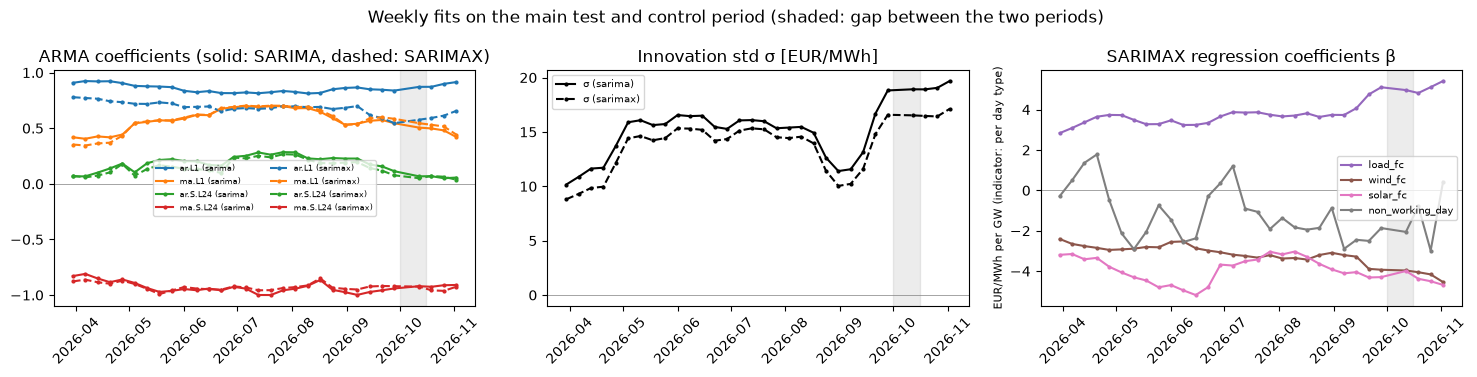

,load_fc,wind_fc,solar_fc,non_working_day
mean,3.85,-3.21,-3.96,-1.19
min,2.83,-4.54,-5.18,-2.98
50%,3.73,-3.18,-3.99,-1.45
max,5.41,-2.41,-3.03,1.78


In [ ]:
arma = ["ar.L1", "ma.L1", "ar.S.L24", "ma.S.L24"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, ls in [("sarima", "-"), ("sarimax", "--")]:
    f = pd.concat([fits[name], fits_control[name]]).set_index("fit_day")
    for k, p in enumerate(arma):
        axes[0].plot(f.index, f[p], ls=ls, marker="o", ms=2, color=f"C{k}", label=f"{p} ({name})")
    axes[1].plot(f.index, np.sqrt(f["sigma2"]), ls=ls, marker="o", ms=2, color="k", label=f"σ ({name})")
f = pd.concat([fits["sarimax"], fits_control["sarimax"]]).set_index("fit_day")
for k, p in enumerate(cfg.EXOG):
    axes[2].plot(f.index, f[p], marker="o", ms=2, color=f"C{k + 4}", label=p)
axes[0].set_title("ARMA coefficients (solid: SARIMA, dashed: SARIMAX)")
axes[1].set_title("Innovation std σ [EUR/MWh]")
axes[2].set_title("SARIMAX regression coefficients β")
axes[2].set_ylabel("EUR/MWh per GW (indicator: per day type)", fontsize=8)
for ax in axes:
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvspan(cfg.TEST_END + pd.Timedelta(days=1), cfg.CONTROL_START, color="grey", alpha=0.15)
    ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(fontsize=6, ncol=2)
axes[1].legend(fontsize=7)
axes[2].legend(fontsize=7)
fig.suptitle("Weekly fits on the main test and control period (shaded: gap between the two periods)")
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "sarima_sarimax_parameters.png", dpi=150)
plt.show()

f[cfg.EXOG].describe().loc[["mean", "min", "50%", "max"]].round(2)

**Observations.**
- **All 62 fits converged** (31 per model), without warnings, in at most 77 iterations.
- **ARMA coefficients are stable** over the 31 weekly fits and close to the pre-test fit (`02_exploration.ipynb`, section 7.3). The seasonal MA coefficient stays between −0.81 and −1.00 (on the invertibility boundary for one SARIMA fit), close to −1: the seasonal difference (1−B²⁴) is then almost cancelled by (1+Θ₁B²⁴), and the model behaves like a slowly updated daily profile plus short-term ARMA dynamics.
- SARIMAX has a lower AR coefficient (0.55–0.78 instead of 0.81–0.92): part of the hour-to-hour persistence of the price is explained by the persistence of load, wind and solar.
- **σ (innovation std)** rises from 9–10 EUR/MWh in April to 14–16 in summer and 17–20 in the control period (more volatile prices). The covariates lower σ only by 0.7–2.6 EUR/MWh in-sample: σ measures 1-hour-ahead errors, for which the last price already carries most of the information. The covariates matter much more over a 1–24 h horizon (section 4).
- **Regression coefficients** have the signs of the merit order on every fit: **load +2.8 to +5.4** EUR/MWh per GW of forecast load, **wind −2.4 to −4.5** and **solar −3.0 to −5.2** EUR/MWh per GW of forecast generation. All three are clearly significant (|z| > 5 on the fit of 29 June printed in section 5). The load and wind effects grow in autumn.
- `non_working_day` is unstable (−3.0 to +1.8, changing sign) and not significant (p = 0.95 on the 29 June fit): once the load forecast is in the model, which is already lower on weekends and holidays, the day type adds little. It is kept, as the protocol fixes the same four exogenous variables for SARIMAX and the foundation models.

## 4. Results

MAE and RMSE in EUR/MWh, and rMAE (MAE / MAE of `naive_ref` on the same days). The naives are recalled for scale (`03_baselines.ipynb`). No quantiles, so no pinball loss. Diebold-Mariano tests and the comparison with the foundation models are in `06_results.ipynb`.

In [ ]:
def summary(results: dict) -> pd.DataFrame:
    ref_mae = mae(results["naive_ref"]["y_true"], results["naive_ref"]["y_pred"])
    return pd.DataFrame({
        name: {
            "MAE": mae(r["y_true"], r["y_pred"]),
            "rMAE": mae(r["y_true"], r["y_pred"]) / ref_mae,
            "RMSE": rmse(r["y_true"], r["y_pred"]),
            "days": r["target_date"].nunique(),
        }
        for name, r in results.items()
    }).T.astype({"days": int})

order = ["naive_ref", "naive_d1", "sarima", "sarimax"]
table = pd.concat({"main test": summary({n: res[n] for n in order}), "control": summary({n: res_control[n] for n in order})})
table.round(3)

MAE   rMAE     RMSE  days
main test naive_ref  35.049  1.000   56.978   183
          naive_d1   33.040  0.943   53.696   183
          sarima     29.382  0.838   45.642   183
          sarimax    17.878  0.510   31.218   183
control   naive_ref  73.293  1.000  102.684    24
          naive_d1   39.491  0.539   56.869    24
          sarima     46.973  0.641   61.222    24
          sarimax    23.629  0.322   30.390    24

### 4.1 Error by hour of day and by day of week

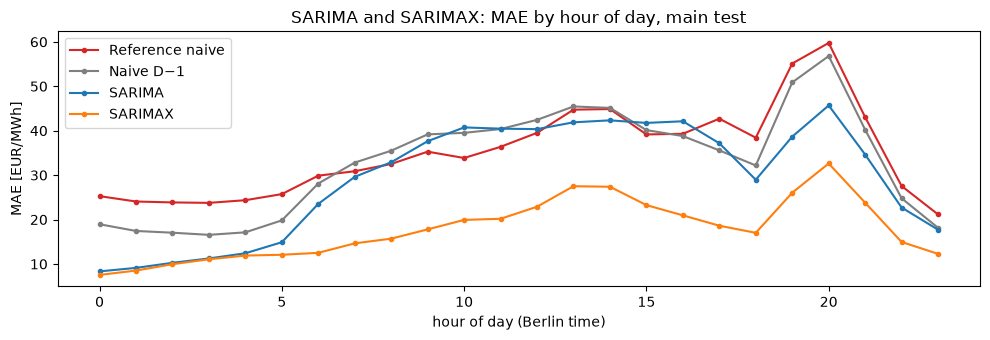

,naive_ref,naive_d1,sarima,sarimax
Mon,50.71,50.59,36.04,19.18
Tue,33.90,33.90,28.90,17.95
Wed,22.58,22.58,25.09,16.76
Thu,29.01,29.01,23.11,18.07
Fri,26.72,26.72,26.77,17.93
Sat,40.38,44.12,33.31,18.20
Sun,42.51,24.77,32.62,17.11


In [ ]:
def mae_by(results: dict, key) -> pd.DataFrame:
    return pd.DataFrame({
        name: r.assign(err=(r["y_true"] - r["y_pred"]).abs()).groupby(key(r))["err"].mean()
        for name, r in results.items()
    })

labels["naive_d1"] = "Naive D−1"
by_hour = mae_by({n: res[n] for n in order}, lambda r: r["hour"])
ax = by_hour.rename(columns=labels).plot(figsize=(10, 3.5), marker="o", ms=3, color=[colors[c] for c in by_hour])
ax.set_xlabel("hour of day (Berlin time)")
ax.set_ylabel("MAE [EUR/MWh]")
ax.set_title("SARIMA and SARIMAX: MAE by hour of day, main test")
plt.tight_layout()
plt.show()

by_dow = mae_by({n: res[n] for n in order}, lambda r: r["target_date"].dt.day_of_week)
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow.round(2)

### 4.2 First look at the covariate gain

SARIMA → SARIMAX on the main test, split by the conditions of CLAUDE.md section 7: working vs non-working days, quartiles of the daily mean wind forecast, hours with a negative price. The full comparison with the foundation models (same splits) is in `06_results.ipynb`.

In [ ]:
main = res["sarima"][["target_date", "hour", "y_true"]].assign(
    err_sarima=(res["sarima"]["y_true"] - res["sarima"]["y_pred"]).abs(),
    err_sarimax=(res["sarimax"]["y_true"] - res["sarimax"]["y_pred"]).abs(),
)
assert (res["sarimax"][["target_date", "hour"]].to_numpy() == main[["target_date", "hour"]].to_numpy()).all()

day_info = df.loc[cfg.TEST_START : cfg.TEST_END + 23 * ONE_HOUR].groupby(lambda t: t.normalize()).agg(
    wind=("wind_fc", "mean"), non_working=("non_working_day", "max"))
main["day type"] = main["target_date"].map(day_info["non_working"]).map({0: "working", 1: "non-working"})
main["wind quartile"] = main["target_date"].map(pd.qcut(day_info["wind"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"]))
main["price < 0"] = np.where(main["y_true"] < 0, "negative hours", "other hours")

def gain(group: str) -> pd.DataFrame:
    t = main.groupby(group, observed=True).agg(
        hours=("y_true", "size"), MAE_sarima=("err_sarima", "mean"), MAE_sarimax=("err_sarimax", "mean"))
    t["gain [%]"] = 100 * (1 - t["MAE_sarimax"] / t["MAE_sarima"])
    return t

pd.concat({g: gain(g) for g in ["day type", "wind quartile", "price < 0"]}).round(2)

hours  MAE_sarima  MAE_sarimax  gain [%]
day type      non-working      1368       33.13        18.53     44.07
              working          3024       27.69        17.58     36.49
wind quartile Q1 (low)         1104       31.86        21.18     33.54
              Q2               1104       26.56        16.68     37.20
              Q3               1080       25.74        15.78     38.71
              Q4 (high)        1104       33.28        17.83     46.41
price < 0     negative hours    425       47.15        24.78     47.46
              other hours      3967       27.48        17.14     37.62

**Observations.**
- **SARIMAX: MAE 17.9 EUR/MWh on the main test (rMAE 0.51)**, against 29.4 for SARIMA (rMAE 0.84): the covariates cut the MAE by **39 %** and the RMSE by 32 %. SARIMA alone beats the naives but not Holt-Winters (MAE 28.2, rMAE 0.80, `03_baselines.ipynb`): with prices only, a daily season and an 8-week window, the extra ARMA structure does not help over a "last price + weekly profile" forecast.
- **By hour**: during the night, SARIMA and SARIMAX are equal (8–12 EUR/MWh): close to the last observed price, the ARMA dynamics dominate. From 06:00, SARIMA quickly reaches the error of the naives, while SARIMAX stays far below all day. The gain is largest at midday (solar) and at the evening peak (20:00: 46 → 33 EUR/MWh).
- **By day of week**: SARIMAX is almost flat (17–19 EUR/MWh every day). SARIMA is worst on Monday, Saturday and Sunday: its daily season (s = 24) cannot anticipate the change between working and non-working days. The load forecast does.
- **Covariate gain by condition**: largest where renewables set the price: on **negative-price hours** (MAE 47.2 → 24.8, −47 %), on **high-wind days** (Q4, −46 %) and on **non-working days** (−44 %). It is smallest on low-wind days (Q1, −34 %), when gas plants set the price: gas and CO₂ prices are not in the model (CLAUDE.md section 10). The first-week plot (section 1.1) shows it: SARIMA misses the negative prices of Sunday 5 and Monday 6 April, SARIMAX sees them coming from the wind and solar forecasts.
- **Control period**: SARIMAX MAE 23.6 (rMAE 0.32), SARIMA 47.0 (rMAE 0.64), worse than `naive_d1` (39.5). The covariate gain is even larger (−50 %) in this turbulent autumn period. As noted in `03_baselines.ipynb`, the rMAE level of the control period is not comparable with the main test; compare models with each other on the same period.

## 5. Residual diagnostics on a few refits

As in the order selection (`02_exploration.ipynb`, section 7.3): `plot_diagnostics` and Ljung-Box test (H₀: no autocorrelation up to the lag; `model_df` = number of ARMA parameters) on the in-sample residuals of three weekly fits of the main test: the first (spring), one in the middle (summer) and the last (autumn). The first residuals, used to initialise the seasonal difference (`loglikelihood_burn`), are dropped. These are the same fits as in the rolling run (same window, same default estimation).

In [ ]:
diag_mondays = pd.to_datetime(["2026-03-30", "2026-06-29", "2026-09-28"])
assert (diag_mondays.day_of_week == 0).all()
n_arma = cfg.SARIMA_ORDER[0] + cfg.SARIMA_ORDER[2] + cfg.SARIMA_SEASONAL_ORDER[0] + cfg.SARIMA_SEASONAL_ORDER[2]

diag_fits, lb_rows = {}, []
for name in ["sarima", "sarimax"]:
    for monday in diag_mondays:
        r = Sarima(exog=cfg.EXOG if name == "sarimax" else None).fit(df.loc[: monday - ONE_HOUR])
        diag_fits[name, monday] = r
        resid = r.resid.iloc[r.loglikelihood_burn :]
        lb = acorr_ljungbox(resid, lags=[24, 48, 168], model_df=n_arma)
        lb_rows.append({
            "model": name, "fit day": monday.date(),
            **{f"LB p-value, lag {lag}": lb.loc[lag, "lb_pvalue"] for lag in [24, 48, 168]},
            "resid std": resid.std(), "kurtosis": resid.kurt(),
        })
pd.DataFrame(lb_rows).set_index(["model", "fit day"]).round(4)

LB p-value, lag 24  LB p-value, lag 48  \
model   fit day                                              
sarima  2026-03-30              0.0015              0.0007   
        2026-06-29              0.0000              0.0000   
        2026-09-28              0.0000              0.0000   
sarimax 2026-03-30              0.0000              0.0000   
        2026-06-29              0.0000              0.0000   
        2026-09-28              0.0000              0.0001   

                    LB p-value, lag 168  resid std  kurtosis  
model   fit day                                               
sarima  2026-03-30               0.0020    10.1913    6.9521  
        2026-06-29               0.0005    15.3916   23.6895  
        2026-09-28               0.0130    18.9536   44.3918  
sarimax 2026-03-30               0.0003     8.8413    7.9189  
        2026-06-29               0.0035    14.4641   31.0557  
        2026-09-28               0.1215    16.6946   61.6743

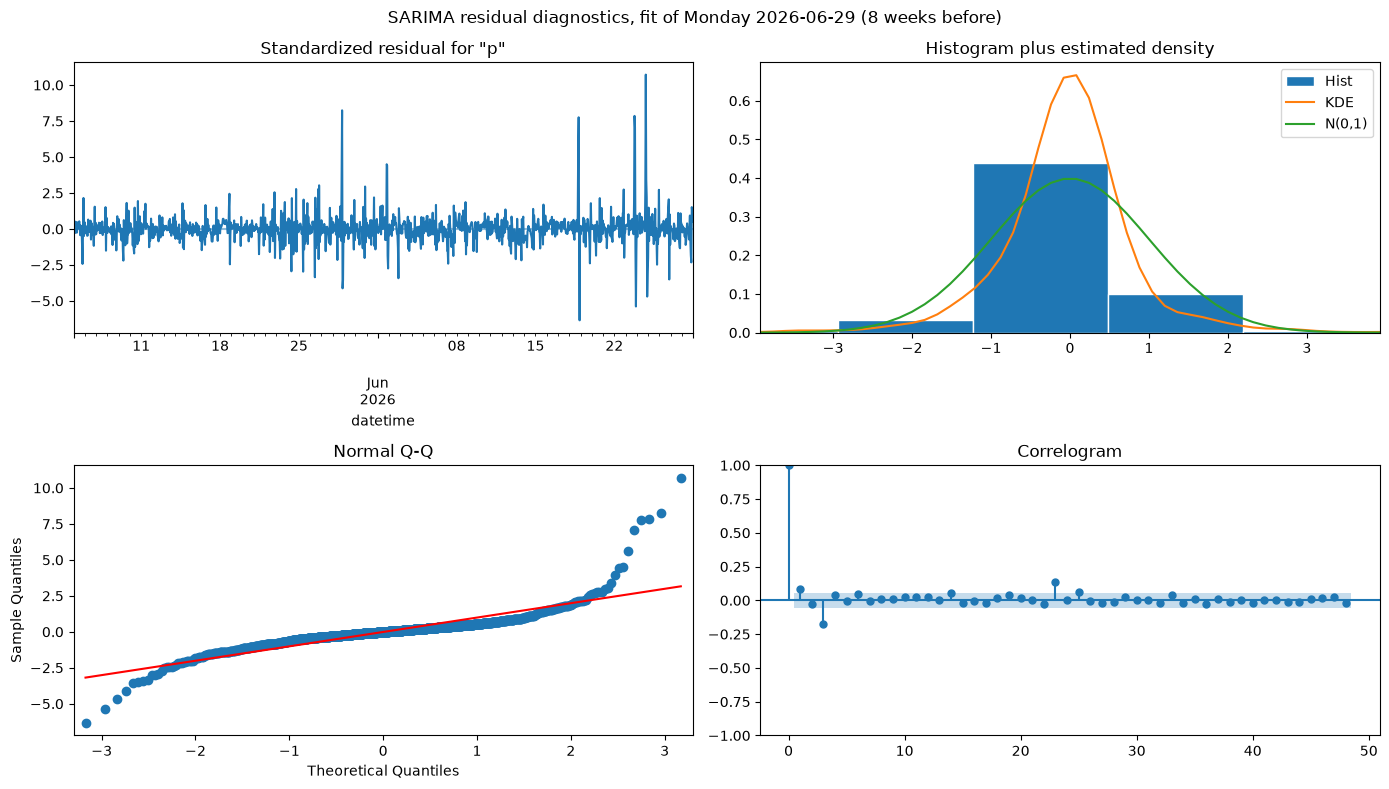

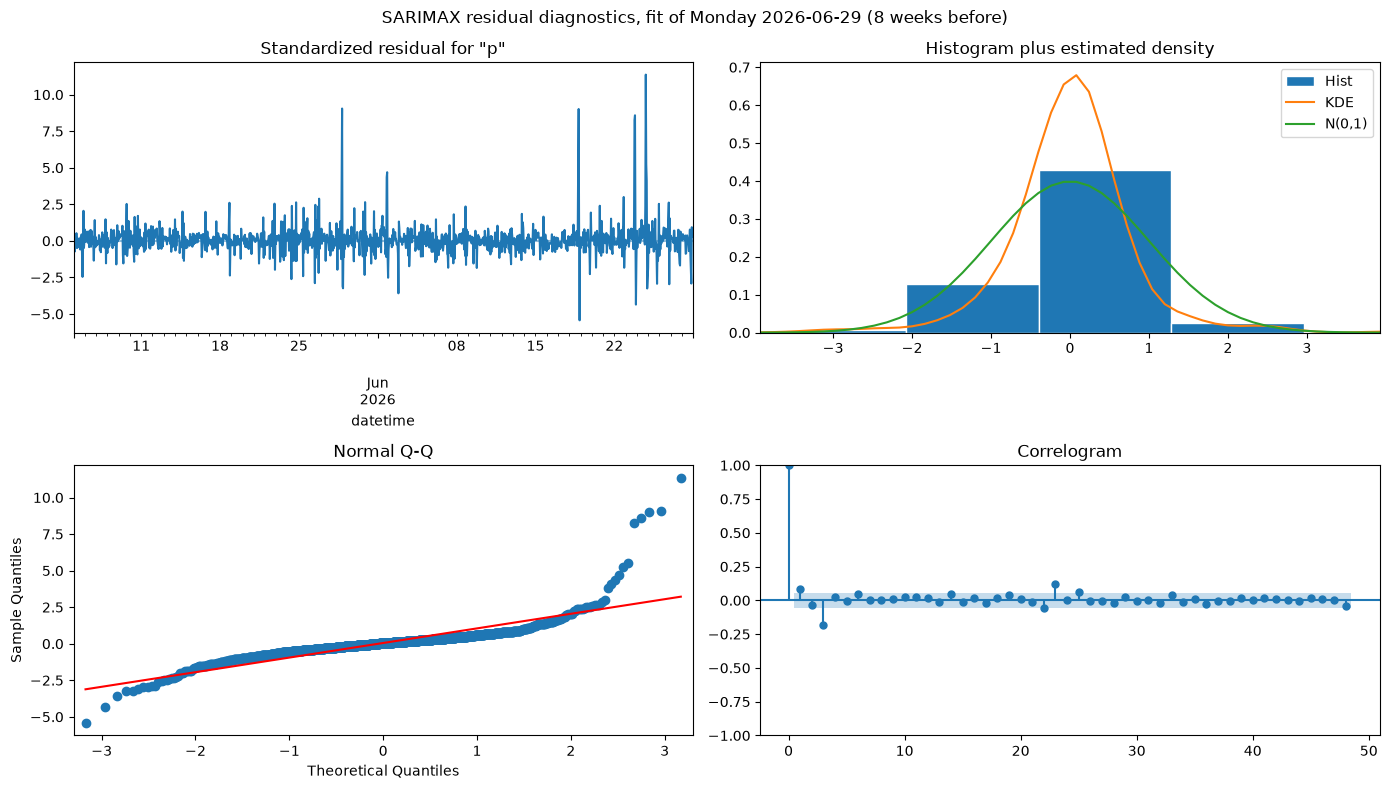

In [ ]:
for name in ["sarima", "sarimax"]:
    r = diag_fits[name, diag_mondays[1]]
    fig = r.plot_diagnostics(figsize=(14, 8), lags=48)
    fig.suptitle(f"{labels[name]} residual diagnostics, fit of Monday {diag_mondays[1].date()} (8 weeks before)")
    fig.tight_layout()
    fig.savefig(cfg.FIGURES_DIR / f"{name}_residual_diagnostics_test.png", dpi=150)
    plt.show()

In [ ]:
print(diag_fits["sarimax", diag_mondays[1]].summary())

                                     SARIMAX Results                                      
Dep. Variable:                              price   No. Observations:                 1344
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood               -5407.204
Date:                            Thu, 19 Nov 2026   AIC                          10832.407
Time:                                    12:05:19   BIC                          10879.076
Sample:                                05-04-2026   HQIC                         10849.904
                                     - 06-28-2026                                         
Covariance Type:                              opg                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
load_fc             3.6592      0.615      5.948      0.000       2.453       4.865
wind_fc            -

**Observations.**
- **Ljung-Box** rejects white-noise residuals at lags 24 and 48 on all six fits (p ≤ 0.002), and at lag 168 on all but one (SARIMAX, 28 September: p = 0.12). The correlogram shows that the remaining autocorrelations are small: within ±0.1 except at lag 3 (≈ −0.18) and around lag 24. As in the order selection, with 1,344 observations the test detects small leftover structure (weekly cycle, spikes) that the frozen low-order model cannot capture. It does not separate SARIMA from SARIMAX.
- **Heavy tails**: excess kurtosis from 7 (spring) to 44–62 (autumn), with a positive skew (3.2 on 29 June): upward price spikes of 5 to 11 standard deviations. The Q-Q plot moves away from the line at both ends, and Jarque-Bera rejects normality.
- **Changing variance**: the heteroskedasticity test rejects (H = 4.2 on 29 June) and the residual std grows from spring to autumn (≈ 9–10 → 17–19 EUR/MWh). The Gaussian prediction intervals of SARIMA/SARIMAX would be too narrow in turbulent periods; this is why no quantiles are reported for them (the pinball loss is only computed for the foundation models, CLAUDE.md section 7).
- SARIMAX residuals are smaller than SARIMA's on the same windows (std −0.9 to −2.3 EUR/MWh) but have the same shape.

These are the limitations accepted when the order was frozen (`02_exploration.ipynb`, section 7.4). They concern the error distribution and the intervals more than the point forecasts evaluated with MAE. Volatility clustering would call for a GARCH-type model (later in the course).

## 6. Summary

| | MAE main test | rMAE main test | MAE control | rMAE control |
|---|---|---|---|---|
| `sarima` | 29.4 | 0.84 | 47.0 | 0.64 |
| `sarimax` | **17.9** | **0.51** | **23.6** | **0.32** |

- **The covariates are worth a lot in the classical family**: −39 % MAE on the main test, −50 % on the control period, with the largest gains on negative-price hours, windy days and non-working days. This is the "classical" row of the two-way table; the comparison with the foundation models and the Diebold-Mariano tests are in `06_results.ipynb`.
- The regression coefficients follow the merit order (load +, wind −, solar −) and are stable from week to week; `non_working_day` adds little once the load forecast is in the model.
- SARIMA without covariates is only slightly better than the naives and behind Holt-Winters on the main test.
- Estimation: weekly refits on Monday, daily `append(refit=False)` in between; all 62 fits converged once the L-BFGS iteration budget was raised from 50 to 1,000 (optimizer setting, section 3.1).
- Residuals: not white noise (Ljung-Box), heavy-tailed and heteroskedastic, as on the pre-test period.